# Ejercicio Binning, imputacion, outliers, dummies etc
El siguiente Dataset contiene detalles de 1000 potenciales compradores de bicicletas, realizaremos un análisis exploratorio del mismo, imputando las variables que correspondan.

1. ¿Cuáles de las variables contienen valores nulos?
2. ¿Está Balanceada la variable target 'Purchased Bike'?
3. Imputar los valores nulos de Gender con el valor 'X'.
4. Imputar los valores nulos y outliers de Age con la media.
5. Eliminar los registros con valor nulo en Cars.
6. Generar columnas dummy para las variables Education y Occupation.
7. Definir una estrategia de imputación para las otras variables que corresponda.
8. Finalizar el análisis exploratorio con gráficos del dataset.

In [26]:
import pandas as pd
bike_buyers = pd.read_csv('https://raw.githubusercontent.com/pokengineer/DataScience/main/datasets/bike_buyers.csv')

In [2]:
bike_buyers.describe(include='all')

,ID,Marital Status,Gender,Income,Children,Education,Occupation,Home Owner,Cars,Commute Distance,Region,Age,Purchased Bike
count,1000.000000,993,989,994.000000,992.000000,1000,1000,996,991.000000,1000,1000,993.000000,1000
unique,NaN,2,2,NaN,NaN,5,5,2,NaN,5,3,NaN,2
top,NaN,Married,Male,NaN,NaN,Bachelors,Professional,Yes,NaN,0-1 Miles,North America,NaN,No
freq,NaN,535,500,NaN,NaN,306,276,682,NaN,366,508,NaN,519
mean,19965.992000,NaN,NaN,56267.605634,1.910282,NaN,NaN,NaN,1.455096,NaN,NaN,44.139980,NaN
std,5347.333948,NaN,NaN,31067.817462,1.626910,NaN,NaN,NaN,1.121755,NaN,NaN,12.338209,NaN
min,11000.000000,NaN,NaN,10000.000000,0.000000,NaN,NaN,NaN,0.000000,NaN,NaN,-28.000000,NaN
25%,15290.750000,NaN,NaN,30000.000000,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,35.000000,NaN
50%,19744.000000,NaN,NaN,60000.000000,2.000000,NaN,NaN,NaN,1.000000,NaN,NaN,43.000000,NaN
75%,24470.750000,NaN,NaN,70000.000000,3.000000,NaN,NaN,NaN,2.000000,NaN,NaN,52.000000,NaN


In [28]:
#1. ¿Cuáles de las variables contienen valores nulos?
bike_buyers.isnull().sum()

ID                   0
Marital Status       7
Gender              11
Income               6
Children             8
Education            0
Occupation           0
Home Owner           4
Cars                 9
Commute Distance     0
Region               0
Age                  7
Purchased Bike       0
dtype: int64

In [21]:
bike_buyers.Gender.isnull()
#bike_buyers['Gender'].iloc[3]

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Name: Gender, Length: 1000, dtype: bool

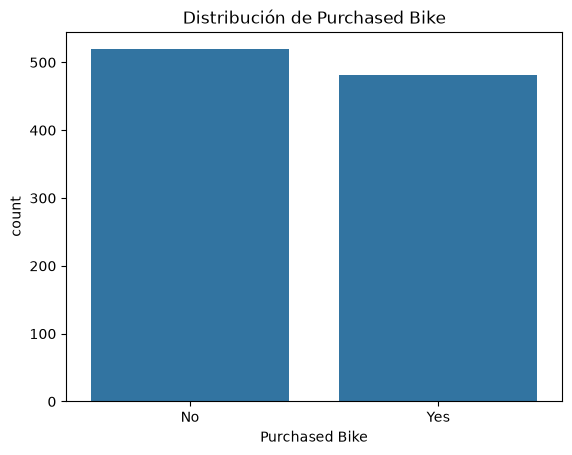

In [12]:
#2. ¿Está Balanceada la variable target 'Purchased Bike'?
#bike_buyers['Purchased Bike'].value_counts()
#bike_buyers['Purchased Bike'].value_counts(normalize=True) * 100
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=bike_buyers, x='Purchased Bike')
plt.title('Distribución de Purchased Bike')
plt.show()

In [46]:
bike_buyers['Purchased Bike'].value_counts()

Purchased Bike
No     514
Yes    477
Name: count, dtype: int64

In [14]:
#3. Imputar los valores nulos de Gender con el valor 'X'.
bike_buyers['Gender'] = bike_buyers['Gender'].fillna('X')
bike_buyers['Gender']

0      Female
1        Male
2        Male
3           X
4        Male
        ...  
995      Male
996      Male
997         X
998      Male
999      Male
Name: Gender, Length: 1000, dtype: str

In [ ]:
#4. Imputar los valores nulos y outliers de Age con la media.
media_age = bike_buyers['Age'].mean()
print(media_age)
bike_buyers['Age'] = bike_buyers['Age'].fillna(media_age)
bike_buyers['Age']

44.139979859013096


0      42.0
1      43.0
2      60.0
3      41.0
4      36.0
       ... 
995    54.0
996    35.0
997    38.0
998    38.0
999    53.0
Name: Age, Length: 1000, dtype: float64

In [ ]:
#5. Eliminar los registros con valor nulo en Cars.
bike_buyers.Cars.isnull().sum()
bike_buyers = bike_buyers.dropna(subset=['Cars'])
bike_buyers.Cars.isnull().sum()

np.int64(0)

In [ ]:
#6. Generar columnas dummy para las variables Education y Occupation.
bike_buyers = pd.get_dummies(bike_buyers, columns=['Education', 'Occupation'])
bike_buyers.head()

,ID,Marital Status,Gender,Income,Children,Home Owner,Cars,Commute Distance,Region,Age,...,Education_Bachelors,Education_Graduate Degree,Education_High School,Education_Partial College,Education_Partial High School,Occupation_Clerical,Occupation_Management,Occupation_Manual,Occupation_Professional,Occupation_Skilled Manual
0,12496,Married,Female,40000.0,1.0,Yes,0.0,0-1 Miles,Europe,42.0,...,True,False,False,False,False,False,False,False,False,True
1,24107,Married,Male,30000.0,3.0,Yes,1.0,0-1 Miles,Europe,43.0,...,False,False,False,True,False,True,False,False,False,False
2,14177,Married,Male,80000.0,5.0,No,2.0,2-5 Miles,Europe,60.0,...,False,False,False,True,False,False,False,False,True,False
3,24381,Single,NaN,70000.0,0.0,Yes,1.0,5-10 Miles,Pacific,41.0,...,True,False,False,False,False,False,False,False,True,False
4,25597,Single,Male,30000.0,0.0,No,0.0,0-1 Miles,Europe,36.0,...,True,False,False,False,False,True,False,False,False,False


In [47]:
#7. Definir una estrategia de imputación para las otras variables que corresponda.
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)

bike_buyers[['Children']] = imputer.fit_transform(
    bike_buyers[['Children']]
)

bike_buyers[['Children']].isnull().sum()
#VER QUE POSICIONES

bike_buyers['Children'].iloc[117]


np.float64(5.0)

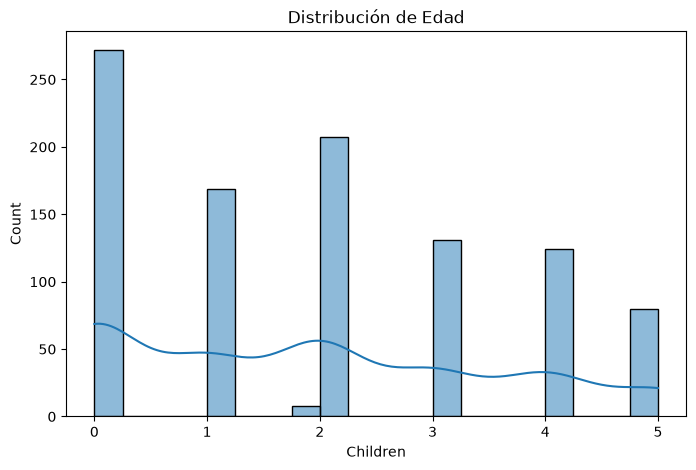

In [45]:
#8. Finalizar el análisis exploratorio con gráficos del dataset.
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.histplot(bike_buyers['Children'], bins=20, kde=True)
plt.title('Distribución de Edad')
plt.show()